# 4.5.3 Stacking à 3 modèles : texte + image + CNN, Dataset 2 (extrait final, 60 000 images)

On ajoute le CNN (4.3) au stacking de 4.5.2. Le CNN est en PyTorch et `StackingClassifier` ne peut pas
l'entraîner : on fait à la main ce qu'il fait, avec les probabilités du train obtenues par validation
croisée (enregistrées en 4.3 et 4.5.2), puis on entraîne la régression logistique dessus.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

from outils_4 import ARTEFACTS_60K, ARTEFACTS_DATASET_1, CLASSES, load_corpus_60k, load_probas

train, test = load_corpus_60k()
y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()

MODELES = ["texte", "image", "cnn"]
oof = {m: load_probas(f"{ARTEFACTS_60K}/probas_{m}_oof.parquet", train["filepath"]) for m in MODELES}
probas_test = {m: load_probas(f"{ARTEFACTS_60K}/probas_{m}_test.parquet", test["filepath"]) for m in MODELES}


def fit_stacking(modeles, meta=None):
    """méta-modèle entraîné sur les probas du train des modèles choisis"""
    if meta is None:
        meta = LogisticRegression(max_iter=2000, random_state=42)
    return meta.fit(np.hstack([oof[m] for m in modeles]), y_train)

## 1. Huit configurations

In [2]:
predictions = {nom: np.array(CLASSES)[probas_test[m].argmax(axis=1)]
               for nom, m in [("Texte seul", "texte"), ("Image seule", "image"), ("CNN seul", "cnn")]}
for nom, modeles in [("Stacking texte + image", ["texte", "image"]), ("Stacking texte + CNN", ["texte", "cnn"]),
                     ("Stacking texte + image + CNN", MODELES)]:
    predictions[nom] = fit_stacking(modeles).predict(np.hstack([probas_test[m] for m in modeles]))

predictions["Stacking à 3, méta-modèle GradientBoosting"] = fit_stacking(
    MODELES, GradientBoostingClassifier(random_state=42)).predict(np.hstack([probas_test[m] for m in MODELES]))

# voting soft à 3 : on essaie tous les poids (pas de 0,05) et on garde le meilleur sur le train
meilleur, poids = -1, None
for w_texte, w_image in itertools.product(np.round(np.arange(0, 1.01, 0.05), 2), repeat=2):
    w_cnn = round(1 - w_texte - w_image, 2)
    if w_cnn < 0:
        continue
    melange = w_texte * oof["texte"] + w_image * oof["image"] + w_cnn * oof["cnn"]
    acc = accuracy_score(y_train, np.array(CLASSES)[melange.argmax(axis=1)])
    if acc > meilleur:
        meilleur, poids = acc, (w_texte, w_image, w_cnn)
melange = sum(w * probas_test[m] for w, m in zip(poids, MODELES))
predictions["Voting soft à 3 (poids texte {:.2f}, image {:.2f}, CNN {:.2f})".format(*poids)] = np.array(CLASSES)[melange.argmax(axis=1)]

facture = y_test == "invoice"
pd.DataFrame([{"configuration": nom, "accuracy": accuracy_score(y_test, p), "recall invoice": (p[facture] == "invoice").mean()}
              for nom, p in predictions.items()]).round(3)

,configuration,accuracy,recall invoice
0,Texte seul,0.867,0.890
1,Image seule,0.777,0.805
2,CNN seul,0.851,0.835
3,Stacking texte + image,0.895,0.910
4,Stacking texte + CNN,0.916,0.917
5,Stacking texte + image + CNN,0.919,0.927
6,"Stacking à 3, méta-modèle GradientBoosting",0.918,0.930
7,"Voting soft à 3 (poids texte 0.50, image 0.20,...",0.915,0.927


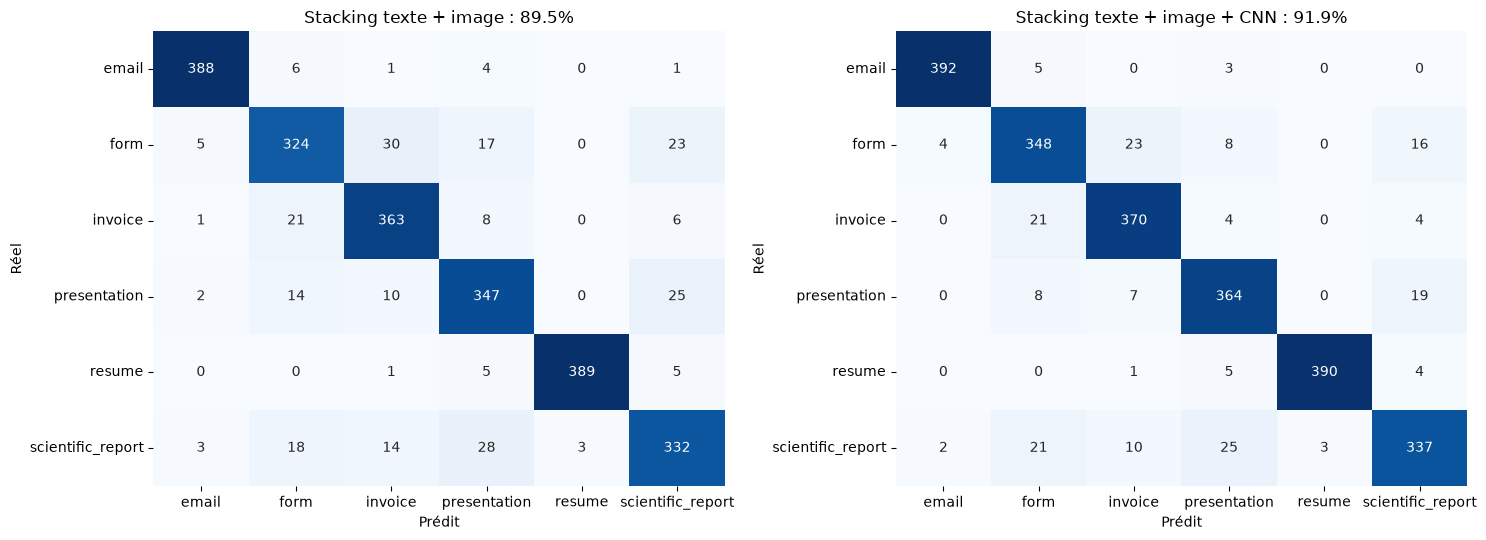

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, nom in zip(axes, ["Stacking texte + image", "Stacking texte + image + CNN"]):
    matrice = pd.crosstab(y_test, predictions[nom], rownames=["Réel"], colnames=["Prédit"])
    sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{nom} : {accuracy_score(y_test, predictions[nom]):.1%}")
plt.tight_layout()
plt.show()

## 2. Le gain dépend-il du découpage de la validation croisée ?

Les 5 découpages de 4.5.2 pour le texte et l'image ; le CNN garde un seul découpage, trop long à
refaire.

In [4]:
lignes = []
for graine in range(5):
    p_texte = load_probas(f"{ARTEFACTS_60K}/probas_texte_oof_r{graine}.parquet", train["filepath"])
    p_image = load_probas(f"{ARTEFACTS_60K}/probas_image_oof_r{graine}.parquet", train["filepath"])
    deux = LogisticRegression(max_iter=2000, random_state=42).fit(np.hstack([p_texte, p_image]), y_train)
    trois = LogisticRegression(max_iter=2000, random_state=42).fit(np.hstack([p_texte, p_image, oof["cnn"]]), y_train)
    lignes.append({"découpage": graine,
                   "texte + image": accuracy_score(y_test, deux.predict(np.hstack([probas_test["texte"], probas_test["image"]]))),
                   "texte + image + CNN": accuracy_score(y_test, trois.predict(np.hstack([probas_test[m] for m in MODELES])))})

robustesse = pd.DataFrame(lignes)
robustesse["gain du CNN"] = robustesse["texte + image + CNN"] - robustesse["texte + image"]
print(f"Le CNN fait gagner {robustesse['gain du CNN'].mean():+.2%} en moyenne, "
      f"positif dans {(robustesse['gain du CNN'] > 0).sum()}/5 découpages")
robustesse.round(4)

Le CNN fait gagner +2.52% en moyenne, positif dans 5/5 découpages


,découpage,texte + image,texte + image + CNN,gain du CNN
0,0,0.8952,0.9194,0.0242
1,1,0.8926,0.9198,0.0272
2,2,0.8943,0.9198,0.0255
3,3,0.8947,0.9190,0.0242
4,4,0.8939,0.9190,0.0251


## 3. Test sur un autre corpus : le dataset 1

Les modèles entraînés sur le dataset 2 sont appliqués tels quels aux 165 documents du dataset 1.
Accuracy mesurée sur `email` et `resume`, les seules classes communes ; pour `scientific_publication`,
on regarde seulement où ils sont rangés.

In [5]:
dataset_1 = pd.read_csv(f"{ARTEFACTS_DATASET_1}/ocr_corpus.csv", keep_default_na=False)
probas_1 = {m: load_probas(f"{ARTEFACTS_DATASET_1}/probas_{m}.parquet", dataset_1["filepath"]) for m in MODELES}
y_1 = dataset_1["label"].to_numpy()
communes = np.isin(y_1, ["email", "resume"])

predictions_1 = {nom: np.array(CLASSES)[probas_1[m].argmax(axis=1)]
                 for nom, m in [("Texte seul", "texte"), ("Image seule", "image"), ("CNN seul", "cnn")]}
predictions_1["Stacking texte + image + CNN"] = fit_stacking(MODELES).predict(np.hstack([probas_1[m] for m in MODELES]))
print(pd.Series({nom: accuracy_score(y_1[communes], p[communes]) for nom, p in predictions_1.items()},
                name="accuracy sur email + resume").round(3))
pd.crosstab(y_1, predictions_1["Stacking texte + image + CNN"], rownames=["réel (dataset 1)"], colnames=["prédit"])

Texte seul                      0.991
Image seule                     0.936
CNN seul                        0.945
Stacking texte + image + CNN    1.000
Name: accuracy sur email + resume, dtype: float64


prédit,email,invoice,presentation,resume,scientific_report
réel (dataset 1),,,,,
email,55,0,0,0,0
resume,0,0,0,55,0
scientific_publication,0,1,1,0,53
